# Live in match win probability model

### Goal:
    * Create a get_live_win_prob function that will get the live win probabilities of the teams playing
    * Create a get_live_fair_odds function that shows what fair betting odds would be for a match in the current state

These functions will use both StatsBomb data to determine the current state of a game and the elo system we set up in notebook 2

### Data/import

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('..')

import pandas as pd
from src.data_loader import(list_available_competitions,
    load_statsbomb_matches,
    load_statsbomb_events_for_competition,
    load_understat_team_data,
    load_understat_team_data_multi,
    load_fbref_player_stats,
    _read_stat_type_with_retry,
    _flatten_and_prefix_columns,
    load_fbref_player_stats_all,
    load_football_data_odds,
    load_football_data_odds_multi)
from src.prematch_prior import (expected_score, 
    get_empirical_draw_probability, 
    get_team_elo_as_of, 
    get_prematch_prior, 
    HOME_ADVANTAGE, 
    INITIAL_ELO)
from src.live_win_prob_model import get_live_win_prob, get_live_fair_odds, compute_possession_pct, compute_shot_momentum

import sklearn
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import math
import time

from xgboost import XGBClassifier

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, f1_score, roc_auc_score, auc, roc_curve, classification_report, brier_score_loss, log_loss
from sklearn.preprocessing import StandardScaler
from sklearn.isotonic import IsotonicRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.calibration import calibration_curve

### 1. Setup

In [2]:
statsbomb_data = pd.read_parquet('../data/raw/statsbomb_events_all.parquet')
team_elo_history = pd.read_parquet('../data/processed/team_elo_history.parquet')

In [3]:
statsbomb_data.head(10)

,50_50,ball_receipt_outcome,ball_recovery_recovery_failure,block_deflection,block_offensive,carry_end_location,clearance_aerial_won,clearance_body_part,clearance_head,clearance_left_foot,...,goalkeeper_lost_in_play,goalkeeper_shot_saved_to_post,shot_saved_to_post,shot_follows_dribble,goalkeeper_success_out,half_end_early_video_end,league,half_start_late_video_start,goalkeeper_penalty_saved_to_post,goalkeeper_saved_to_post
0,None,None,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,La Liga,None,None,None
1,None,None,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,La Liga,None,None,None
2,None,None,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,La Liga,None,None,None
3,None,None,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,La Liga,None,None,None
4,None,None,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,La Liga,None,None,None
5,None,None,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,La Liga,None,None,None
6,None,None,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,La Liga,None,None,None
7,None,None,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,La Liga,None,None,None
8,None,None,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,La Liga,None,None,None
9,None,None,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,La Liga,None,None,None


In [4]:
statsbomb_data[['type', 'minute', 'team', 'player']].head(10)

,type,minute,team,player
0,Starting XI,0,Real Madrid,None
1,Starting XI,0,Sporting Gijón,None
2,Half Start,0,Real Madrid,None
3,Half Start,0,Sporting Gijón,None
4,Half Start,45,Sporting Gijón,None
5,Half Start,45,Real Madrid,None
6,Pass,0,Sporting Gijón,Miguel Ángel Guerrero Martín
7,Pass,0,Sporting Gijón,Alen Halilović
8,Pass,0,Sporting Gijón,Ignacio Cases Mora
9,Pass,0,Sporting Gijón,Alejandro Menéndez Díez


In [5]:
statsbomb_data.shape

(3962866, 121)

In [6]:
team_elo_history.head(10)

,date,team,elo_post
0,2014-08-31 17:00:00,AC Milan,1532.394150
1,2014-09-14 19:45:00,AC Milan,1566.343889
2,2014-09-20 19:45:00,AC Milan,1528.238505
3,2014-09-23 19:45:00,AC Milan,1528.751468
4,2014-09-28 14:00:00,AC Milan,1529.250842
5,2014-10-04 19:45:00,AC Milan,1552.096062
6,2014-10-19 14:00:00,AC Milan,1609.062317
7,2014-10-26 19:45:00,AC Milan,1600.725779
8,2014-10-29 19:45:00,AC Milan,1604.173889
9,2014-11-02 19:45:00,AC Milan,1526.862796


In [7]:
statsbomb_data[['type', 'minute', 'team', 'player']].describe()
statsbomb_data['type'].value_counts()

type
Pass                 1107574
Ball Receipt*        1027187
Carry                 833940
Pressure              360371
Ball Recovery         120789
Duel                   92702
Clearance              55637
Block                  44482
Dribble                39966
Goal Keeper            35228
Foul Committed         34310
Foul Won               32747
Miscontrol             32408
Dispossessed           29161
Shot                   29074
Interception           29045
Dribbled Past          24594
Substitution            6537
Half End                4560
Half Start              4560
Injury Stoppage         3805
50/50                   2843
Tactical Shift          2583
Starting XI             2280
Shield                  1629
Bad Behaviour            998
Player Off               993
Player On                984
Referee Ball-Drop        823
Error                    470
Offside                  396
Own Goal For              95
Own Goal Against          95
Name: count, dtype: int64

In [8]:
match_list = pd.read_parquet('../data/raw/statsbomb_match_list.parquet')
match_list.head()

,match_id,home_team,away_team,home_score,away_score,match_date,league
0,3825739,Real Madrid,Sporting Gijón,5,1,2016-01-17,La Liga
1,3825848,Levante UD,Eibar,2,2,2015-09-23,La Liga
2,3825895,Las Palmas,Sevilla,2,0,2015-09-23,La Liga
3,3825894,RC Deportivo La Coruña,Getafe,0,2,2016-05-01,La Liga
4,3825855,Málaga,Levante UD,3,1,2016-05-02,La Liga


In [9]:
match_list.columns.tolist()
match_list[['match_id', 'home_team', 'away_team', 'match_date']].head()
print(len(match_list))

1140


In [10]:
bin_edges = np.load('../data/processed/elo_bin_edges.npy')
draw_rate_by_bin = pd.read_pickle('../data/processed/draw_rate_by_bin.pkl')

In [11]:
sample_matches = match_list.head(5)

for _, row in sample_matches.iterrows():
    prior = get_prematch_prior(
        row['home_team'], 
        row['away_team'], 
        row['match_date'],
        team_elo_history, 
        bin_edges, 
        draw_rate_by_bin
    )
    print(row['home_team'], 'vs', row['away_team'], '->', prior)

Real Madrid vs Sporting Gijón -> {'prob_home_win': np.float64(0.802006125415105), 'prob_draw': np.float64(0.17316017316017315), 'prob_away_win': np.float64(0.02483370142472181)}
Levante UD vs Eibar -> {'prob_home_win': np.float64(0.3957422294052581), 'prob_draw': np.float64(0.32867132867132864), 'prob_away_win': np.float64(0.27558644192341325)}
Las Palmas vs Sevilla -> {'prob_home_win': np.float64(0.32870174157797455), 'prob_draw': np.float64(0.26229508196721313), 'prob_away_win': np.float64(0.4090031764548122)}
RC Deportivo La Coruña vs Getafe -> {'prob_home_win': np.float64(0.5223618554582865), 'prob_draw': np.float64(0.27507163323782235), 'prob_away_win': np.float64(0.2025665113038912)}
Málaga vs Levante UD -> {'prob_home_win': np.float64(0.6476071545816402), 'prob_draw': np.float64(0.22756410256410256), 'prob_away_win': np.float64(0.1248287428542573)}


In [12]:
# Write a function to get the probabilities for each match then append it to match_list
def get_prior_for_row(row):
    prior = get_prematch_prior(
        row['home_team'],
        row['away_team'],
        row['match_date'],
        team_elo_history,
        bin_edges,
        draw_rate_by_bin
    )
    return pd.Series(prior)

prior_columns = match_list.apply(get_prior_for_row, axis=1)
match_list = pd.concat([match_list.drop(columns=['prob_home_win', 'prob_draw', 'prob_away_win'], errors='ignore'), prior_columns], axis=1)

In [13]:
# Check the results
match_list[['home_team', 'away_team', 'match_date', 'prob_home_win', 'prob_draw', 'prob_away_win']].head(10)

,home_team,away_team,match_date,prob_home_win,prob_draw,prob_away_win
0,Real Madrid,Sporting Gijón,2016-01-17,0.802006,0.173160,0.024834
1,Levante UD,Eibar,2015-09-23,0.395742,0.328671,0.275586
2,Las Palmas,Sevilla,2015-09-23,0.328702,0.262295,0.409003
3,RC Deportivo La Coruña,Getafe,2016-05-01,0.522362,0.275072,0.202567
4,Málaga,Levante UD,2016-05-02,0.647607,0.227564,0.124829
5,Espanyol,Eibar,2016-05-15,0.489714,0.272727,0.237559
6,Málaga,Las Palmas,2016-05-15,0.407355,0.328671,0.263974
7,Sporting Gijón,Villarreal,2016-05-15,0.332826,0.262295,0.404878
8,Rayo Vallecano,Levante UD,2016-05-15,0.518480,0.275072,0.206448
9,Real Betis,Getafe,2016-05-15,0.534805,0.275072,0.190123


In [14]:
print(match_list.shape)

(1140, 10)


### 2. Data Exploration

In [15]:
# Checkout what types of events are in the dataset
statsbomb_data['type'].value_counts()

type
Pass                 1107574
Ball Receipt*        1027187
Carry                 833940
Pressure              360371
Ball Recovery         120789
Duel                   92702
Clearance              55637
Block                  44482
Dribble                39966
Goal Keeper            35228
Foul Committed         34310
Foul Won               32747
Miscontrol             32408
Dispossessed           29161
Shot                   29074
Interception           29045
Dribbled Past          24594
Substitution            6537
Half End                4560
Half Start              4560
Injury Stoppage         3805
50/50                   2843
Tactical Shift          2583
Starting XI             2280
Shield                  1629
Bad Behaviour            998
Player Off               993
Player On                984
Referee Ball-Drop        823
Error                    470
Offside                  396
Own Goal For              95
Own Goal Against          95
Name: count, dtype: int64

In [16]:
# Get a list of all shot event data types
shot_columns = [col for col in statsbomb_data.columns if col.startswith('shot_')]
print(shot_columns)

['shot_aerial_won', 'shot_body_part', 'shot_end_location', 'shot_first_time', 'shot_freeze_frame', 'shot_key_pass_id', 'shot_one_on_one', 'shot_open_goal', 'shot_outcome', 'shot_statsbomb_xg', 'shot_technique', 'shot_type', 'shot_deflected', 'shot_saved_off_target', 'shot_redirect', 'shot_saved_to_post', 'shot_follows_dribble']


In [17]:
# No goal type which could mean it is under shots
statsbomb_data[statsbomb_data['type'] == 'Shot']['shot_outcome'].value_counts()

shot_outcome
Off T               9653
Blocked             7488
Saved               6626
Goal                2953
Wayward             1601
Post                 550
Saved Off Target     115
Saved to Post         88
Name: count, dtype: int64

In [18]:
statsbomb_data[statsbomb_data['type'] == 'Shot']['shot_statsbomb_xg'].describe()

count    29074.000000
mean         0.098780
std          0.140499
min          0.000180
25%          0.026831
50%          0.050440
75%          0.100555
max          0.995122
Name: shot_statsbomb_xg, dtype: float64

In [19]:
# Check the bad behavior and foul committed sections to see if they have more card data
statsbomb_data[statsbomb_data['foul_committed_card'].notna()]['foul_committed_card'].value_counts()

foul_committed_card
Yellow Card      4267
Second Yellow     162
Red Card           84
Name: count, dtype: int64

In [20]:
statsbomb_data[statsbomb_data['bad_behaviour_card'].notna()]['bad_behaviour_card'].value_counts()

bad_behaviour_card
Yellow Card      948
Red Card          34
Second Yellow     16
Name: count, dtype: int64

In [21]:
goalkeeper_columns = [col for col in statsbomb_data.columns if col.startswith('goalkeeper_')]
print(goalkeeper_columns)

['goalkeeper_body_part', 'goalkeeper_end_location', 'goalkeeper_outcome', 'goalkeeper_position', 'goalkeeper_technique', 'goalkeeper_type', 'goalkeeper_punched_out', 'goalkeeper_success_in_play', 'goalkeeper_shot_saved_off_target', 'goalkeeper_lost_out', 'goalkeeper_lost_in_play', 'goalkeeper_shot_saved_to_post', 'goalkeeper_success_out', 'goalkeeper_penalty_saved_to_post', 'goalkeeper_saved_to_post']


Mental Checklist for Feature building later:
* Goals: check shot_outcome == 'Goal' OR the two own-goal event types
* Red cards / man advantage: check foul_committed_card OR bad_behaviour_card, treating 'Red Card' and 'Second Yellow' as equivalent (both = one fewer player)
* xG: shot_statsbomb_xg, on Shot type events (worth also checking whether this column is populated for own goals — likely not, since an own goal isn't a "shot" by the scoring team, worth a quick check when you get there)

In [22]:
# Check out possesion level data
possession_columns = [col for col in statsbomb_data.columns if 'possession' in col.lower()]
print(possession_columns)

['possession', 'possession_team', 'possession_team_id']


In [23]:
statsbomb_data[['match_id', 'minute', 'second', 'period', 'team', 'possession', 'possession_team']].head(20)

,match_id,minute,second,period,team,possession,possession_team
0,3825739,0,0,1,Real Madrid,1,Real Madrid
1,3825739,0,0,1,Sporting Gijón,1,Real Madrid
2,3825739,0,0,1,Real Madrid,1,Real Madrid
3,3825739,0,0,1,Sporting Gijón,1,Real Madrid
4,3825739,45,0,2,Sporting Gijón,82,Real Madrid
5,3825739,45,0,2,Real Madrid,82,Real Madrid
6,3825739,0,1,1,Sporting Gijón,2,Sporting Gijón
7,3825739,0,1,1,Sporting Gijón,2,Sporting Gijón
8,3825739,0,3,1,Sporting Gijón,2,Sporting Gijón
9,3825739,0,6,1,Sporting Gijón,2,Sporting Gijón


In [24]:
# Look up one possesion spell in isolation
one_match = statsbomb_data[statsbomb_data['match_id'] == statsbomb_data['match_id'].iloc[0]]
one_match[one_match['possession'] == 1][['minute', 'second', 'type', 'team', 'possession_team']]

,minute,second,type,team,possession_team
0,0,0,Starting XI,Real Madrid,Real Madrid
1,0,0,Starting XI,Sporting Gijón,Real Madrid
2,0,0,Half Start,Real Madrid,Real Madrid
3,0,0,Half Start,Sporting Gijón,Real Madrid


In [25]:
print(one_match['match_id'].nunique())

1


In [26]:
# Lookj at duration across events before trying to create a rolling possesion feature
one_match[one_match['possession'] == 2][['minute', 'second', 'type', 'team', 'duration']]

,minute,second,type,team,duration
6,0,1,Pass,Sporting Gijón,0.631284
7,0,1,Pass,Sporting Gijón,1.581410
8,0,3,Pass,Sporting Gijón,2.526950
9,0,6,Pass,Sporting Gijón,0.966365
10,0,8,Pass,Sporting Gijón,3.096724
1183,0,1,Ball Receipt*,Sporting Gijón,NaN
1184,0,3,Ball Receipt*,Sporting Gijón,NaN
1185,0,6,Ball Receipt*,Sporting Gijón,NaN
1186,0,7,Ball Receipt*,Sporting Gijón,NaN
1187,0,11,Ball Receipt*,Sporting Gijón,NaN


In [27]:
# Compare summed durations vs. first to last timestamp gap directly
spell = one_match[one_match['possession'] == 2]
print("Sum of individual durations:", spell['duration'].sum())
print("First event time:", spell[['minute', 'second']].iloc[0].tolist())
print("Last event time:", spell[['minute', 'second']].iloc[-1].tolist())

Sum of individual durations: 11.824852
First event time: [0, 1]
Last event time: [0, 11]


### Building a spell duration for possession feature for the entire dataset

From the event type breakdown above, several types represent match administration
rather than live play and shouldn't count toward possession time: `Starting XI` and
`Half Start`/`Half End` (pre/post-period markers), `Injury Stoppage` (clock stopped),
`Tactical Shift` (a formation marker, not an action), and `Substitution` (a player
change, not ball possession). Excluding these before computing spell durations.

In [28]:
# Filter out non play events
non_play_types = ['Starting XI', 'Half Start', 'Half End', 'Injury Stoppage', 'Tactical Shift', 'Substitution']
play_events = statsbomb_data[~statsbomb_data['type'].isin(non_play_types)].copy()
print(len(play_events), len(statsbomb_data))

3938541 3962866


In [29]:
# Sort properly within each match and spell
play_events = play_events.sort_values(['match_id', 'period', 'minute', 'second']).reset_index(drop=True)
play_events[['match_id', 'period', 'minute', 'second', 'type', 'team']].head(20)

,match_id,period,minute,second,type,team
0,265839,1,0,0,Pass,Barcelona
1,265839,1,0,1,Pass,Barcelona
2,265839,1,0,1,Ball Receipt*,Barcelona
3,265839,1,0,1,Carry,Barcelona
4,265839,1,0,3,Ball Receipt*,Barcelona
5,265839,1,0,3,Carry,Barcelona
6,265839,1,0,4,Pass,Barcelona
7,265839,1,0,6,Ball Receipt*,Barcelona
8,265839,1,0,6,Carry,Barcelona
9,265839,1,0,8,Pass,Barcelona


In [30]:
# Combine minutes and seconds into one row
play_events['total_seconds'] = play_events['minute'] * 60 + play_events['second']

In [31]:
play_events[['match_id', 'period', 'minute', 'second','total_seconds', 'type', 'team']].tail(20)

,match_id,period,minute,second,total_seconds,type,team
3938521,3879876,2,93,29,5609,Pressure,Genoa
3938522,3879876,2,93,30,5610,Pass,Atalanta
3938523,3879876,2,93,32,5612,Pressure,Atalanta
3938524,3879876,2,93,33,5613,Ball Receipt*,Atalanta
3938525,3879876,2,93,34,5614,Foul Committed,Atalanta
3938526,3879876,2,93,34,5614,Foul Won,Genoa
3938527,3879876,2,93,49,5629,Pass,Genoa
3938528,3879876,2,93,50,5630,Ball Receipt*,Genoa
3938529,3879876,2,93,54,5634,Pass,Genoa
3938530,3879876,2,93,55,5635,Ball Receipt*,Genoa


In [32]:
# Compute spell start/end per match
spell_bounds = play_events.groupby(['match_id', 'possession']).agg(
    possession_team=('possession_team', 'first'),
    spell_start=('total_seconds', 'min'),
    spell_end=('total_seconds', 'max')
).reset_index()

spell_bounds['spell_duration'] = spell_bounds['spell_end'] - spell_bounds['spell_start']

In [33]:
print(spell_bounds.shape)
spell_bounds.head(10)
spell_bounds['spell_duration'].describe()

(221885, 6)


count    221885.000000
mean         19.548180
std          94.584946
min           0.000000
25%           5.000000
50%          11.000000
75%          22.000000
max        3023.000000
Name: spell_duration, dtype: float64

In [34]:
# Look at outliers and what may be cause the unrealistic max value
spell_bounds.sort_values('spell_duration', ascending=False).head(10)

,match_id,possession,possession_team,spell_start,spell_end,spell_duration
55544,3754236,89,Crystal Palace,1,3024,3023
70569,3754316,82,Sunderland,0,2988,2988
8096,3753984,88,West Ham United,1,2948,2947
24406,3754071,78,Sunderland,0,2946,2946
67954,3754302,99,Leicester City,0,2944,2944
15272,3754022,95,Crystal Palace,0,2939,2939
59444,3754257,113,Manchester City,0,2934,2934
44855,3754180,99,Sunderland,0,2915,2915
16428,3754028,82,Southampton,0,2914,2914
33423,3754119,76,Newcastle United,0,2912,2912


In [35]:
outlier = play_events[(play_events['match_id'] == 3754236) & (play_events['possession'] == 89)]
outlier[['period', 'minute', 'second', 'total_seconds', 'type', 'team']].sort_values('total_seconds')

,period,minute,second,total_seconds,type,team
1026493,1,0,1,1,Ball Receipt*,Crystal Palace
1028152,1,50,19,3019,Pass,Crystal Palace
1028153,1,50,22,3022,Pass,Crystal Palace
1028154,1,50,22,3022,Ball Receipt*,Crystal Palace
1028155,1,50,24,3024,Pressure,West Bromwich Albion


In [36]:
all_89 = play_events[(play_events['match_id'] == 3754236) & (play_events['possession'] == 89)]
print(len(all_89))
all_89[['minute', 'second', 'total_seconds', 'type', 'team']].sort_values('total_seconds')

5


,minute,second,total_seconds,type,team
1026493,0,1,1,Ball Receipt*,Crystal Palace
1028152,50,19,3019,Pass,Crystal Palace
1028153,50,22,3022,Pass,Crystal Palace
1028154,50,22,3022,Ball Receipt*,Crystal Palace
1028155,50,24,3024,Pressure,West Bromwich Albion


In [37]:
around = play_events[(play_events['match_id'] == 3754236) & (play_events['total_seconds'].between(2, 3018))]
around['possession'].unique()

array([  2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,  14,
        15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,  27,
        28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,  40,
        41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,  53,
        54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,  65,  66,
        67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,  79,
        80,  81,  82,  83,  84,  85,  86,  87,  88,  90,  91,  92,  93,
        94,  95,  96,  97,  98,  99, 100, 101])

In [38]:
# Create a cap to filter unrealistic spell durations
REALISTIC_MAX_SPELL_SECONDS = 120  # generous upper bound; genuine spells rarely exceed ~30-60s

spell_bounds_clean = spell_bounds[spell_bounds['spell_duration'] <= REALISTIC_MAX_SPELL_SECONDS].copy()
print(len(spell_bounds), len(spell_bounds_clean))
spell_bounds_clean['spell_duration'].describe()

221885 221212


count    221212.000000
mean         16.178345
std          16.569835
min           0.000000
25%           5.000000
50%          11.000000
75%          22.000000
max         120.000000
Name: spell_duration, dtype: float64

In [39]:
# Build the snapshot skelton of one row per match per minute
match_durations = play_events.groupby('match_id')['total_seconds'].max().reset_index()
match_durations.columns = ['match_id', 'match_end_seconds']

snapshots = []
for _, row in match_durations.iterrows():
    match_id = row['match_id']
    end_seconds = row['match_end_seconds']
    minute_marks = range(0, math.ceil(end_seconds / 60) + 1)
    for minute in minute_marks:
        snapshots.append({'match_id': match_id, 'snapshot_minute': minute, 'snapshot_seconds': minute * 60})

snapshot_skeleton = pd.DataFrame(snapshots)
print(len(snapshot_skeleton))
snapshot_skeleton.head(10)

108610


,match_id,snapshot_minute,snapshot_seconds
0,265839,0,0
1,265839,1,60
2,265839,2,120
3,265839,3,180
4,265839,4,240
5,265839,5,300
6,265839,6,360
7,265839,7,420
8,265839,8,480
9,265839,9,540


In [40]:
snapshot_skeleton = snapshot_skeleton.merge(
    match_list[['match_id', 'home_team', 'away_team']],
    on='match_id',
    how='left'
)

In [41]:
snapshot_skeleton.head()

,match_id,snapshot_minute,snapshot_seconds,home_team,away_team
0,265839,0,0,Barcelona,Sevilla
1,265839,1,60,Barcelona,Sevilla
2,265839,2,120,Barcelona,Sevilla
3,265839,3,180,Barcelona,Sevilla
4,265839,4,240,Barcelona,Sevilla


In [42]:
# Compute rolling possesion for each snapshot
POSSESSION_WINDOW_SECONDS = 600  # 10 minutes

def compute_possession_pct(row, spell_bounds_clean):
    window_start = row['snapshot_seconds'] - POSSESSION_WINDOW_SECONDS
    window_end = row['snapshot_seconds']
    
    relevant_spells = spell_bounds_clean[
        (spell_bounds_clean['match_id'] == row['match_id']) &
        (spell_bounds_clean['spell_start'] >= window_start) &
        (spell_bounds_clean['spell_start'] < window_end)
    ]
    
    if len(relevant_spells) == 0:
        return pd.Series({'home_possession_pct': 0.5, 'away_possession_pct': 0.5})
    
    team_totals = relevant_spells.groupby('possession_team')['spell_duration'].sum()
    total_time = team_totals.sum()
    
    home_seconds = team_totals.get(row['home_team'], 0)
    away_seconds = team_totals.get(row['away_team'], 0)
    
    return pd.Series({
        'home_possession_pct': home_seconds / total_time,
        'away_possession_pct': away_seconds / total_time
    })

In [43]:
# Test the function before applying it to the entire dataset
test_subset = snapshot_skeleton.head(50)
test_result = test_subset.apply(lambda row: compute_possession_pct(row, spell_bounds_clean), axis=1)
print(test_result.head(10))

   home_possession_pct  away_possession_pct
0             0.500000             0.500000
1             0.945455             0.054545
2             0.730769             0.269231
3             0.812081             0.187919
4             0.858921             0.141079
5             0.786765             0.213235
6             0.769492             0.230508
7             0.722930             0.277070
8             0.743935             0.256065
9             0.760000             0.240000


In [44]:
# Apply the rolling possesion spells to the whole dataset
possession_features = snapshot_skeleton.apply(
    lambda row: compute_possession_pct(row, spell_bounds_clean), axis=1
)

snapshot_skeleton = pd.concat([snapshot_skeleton, possession_features], axis=1)
print(snapshot_skeleton.shape)
snapshot_skeleton.head(10)

(108610, 7)


,match_id,snapshot_minute,snapshot_seconds,home_team,away_team,home_possession_pct,away_possession_pct
0,265839,0,0,Barcelona,Sevilla,0.500000,0.500000
1,265839,1,60,Barcelona,Sevilla,0.945455,0.054545
2,265839,2,120,Barcelona,Sevilla,0.730769,0.269231
3,265839,3,180,Barcelona,Sevilla,0.812081,0.187919
4,265839,4,240,Barcelona,Sevilla,0.858921,0.141079
5,265839,5,300,Barcelona,Sevilla,0.786765,0.213235
6,265839,6,360,Barcelona,Sevilla,0.769492,0.230508
7,265839,7,420,Barcelona,Sevilla,0.722930,0.277070
8,265839,8,480,Barcelona,Sevilla,0.743935,0.256065
9,265839,9,540,Barcelona,Sevilla,0.760000,0.240000


In [45]:
snapshot_skeleton.to_parquet('../data/processed/snapshot_possession_features.parquet')

### Score differential feature

In [46]:
#Build a clean goal events table
own_goals = statsbomb_data[statsbomb_data['type'].isin(['Own Goal For', 'Own Goal Against'])]
own_goals[['match_id', 'minute', 'second', 'type', 'team', 'player']].sort_values(['match_id', 'minute']).head(10)

,match_id,minute,second,type,team,player
1243366,266106,62,3,Own Goal For,Villarreal,Roberto Soldado Rillo
1243367,266106,62,3,Own Goal Against,Barcelona,Jérémy Mathieu
1269200,266160,20,33,Own Goal For,Barcelona,Jordi Alba Ramos
1269201,266160,20,33,Own Goal Against,Levante UD,David Navarro Pedrós
1178088,266498,7,43,Own Goal Against,Getafe,Juan Antonio Rodríguez Villamuela
1178089,266498,7,43,Own Goal For,Barcelona,Gerard Piqué Bernabéu
1295340,266557,25,17,Own Goal For,Valencia,Guilherme Magdalena Siqueira
1295341,266557,25,17,Own Goal Against,Barcelona,Ivan Rakitić
1261721,267327,29,1,Own Goal For,Barcelona,Ivan Rakitić
1261722,267327,29,1,Own Goal Against,Real Betis,Heiko Westermann


In [47]:
# Build the combined goals table
shot_goals = play_events[
    (play_events['type'] == 'Shot') & (play_events['shot_outcome'] == 'Goal')
][['match_id', 'total_seconds', 'team']].copy()
shot_goals['scoring_team'] = shot_goals['team']

own_goals_for = play_events[play_events['type'] == 'Own Goal For'][['match_id', 'total_seconds', 'team']].copy()

In [48]:
print((statsbomb_data['type'] == 'Shot').sum(), (play_events['type'] == 'Shot').sum())
print((statsbomb_data['type'] == 'Own Goal For').sum(), (play_events['type'] == 'Own Goal For').sum())

29074 29074
95 95


In [49]:
# Finish the own goals events to show that own goals are goals for the opposite team
own_goals_for['scoring_team'] = own_goals_for['team']

own_goals_for[['match_id', 'team', 'scoring_team']].head(10)

# Combine both sources into one goal table
all_goals = pd.concat([
    shot_goals[['match_id', 'total_seconds', 'scoring_team']],
    own_goals_for[['match_id', 'total_seconds', 'scoring_team']]
], ignore_index=True)

print(len(all_goals))

# Attach home/away teams to all goals and flag which side scored
all_goals = all_goals.merge(
    match_list[['match_id', 'home_team', 'away_team']],
    on='match_id',
    how='left'
)
all_goals['is_home_goal'] = (all_goals['scoring_team'] == all_goals['home_team']).astype(int)
all_goals['is_away_goal'] = (all_goals['scoring_team'] == all_goals['away_team']).astype(int)

3048


In [50]:
# Sort and compute a running cumulative count
all_goals = all_goals.sort_values(['match_id', 'total_seconds']).reset_index(drop=True)

all_goals['home_goals_cum'] = all_goals.groupby('match_id')['is_home_goal'].cumsum()
all_goals['away_goals_cum'] = all_goals.groupby('match_id')['is_away_goal'].cumsum()

In [51]:
# Bring the cumulative counts onto every snapshot row
snapshot_skeleton = snapshot_skeleton.sort_values('snapshot_seconds').reset_index(drop=True)
all_goals = all_goals.sort_values('total_seconds').reset_index(drop=True)

snapshot_skeleton = pd.merge_asof(
    snapshot_skeleton,
    all_goals[['match_id', 'total_seconds', 'home_goals_cum', 'away_goals_cum']],
    left_on='snapshot_seconds',
    right_on='total_seconds',
    by='match_id',
    direction='backward'
)

In [52]:
# Handle matches with no goals yet
snapshot_skeleton['home_goals_cum'] = snapshot_skeleton['home_goals_cum'].fillna(0)
snapshot_skeleton['away_goals_cum'] = snapshot_skeleton['away_goals_cum'].fillna(0)

snapshot_skeleton['score_diff'] = snapshot_skeleton['home_goals_cum'] - snapshot_skeleton['away_goals_cum']

In [53]:
# Check results
check_match = snapshot_skeleton[snapshot_skeleton['match_id'] == 3825739]
check_match[['snapshot_minute', 'home_goals_cum', 'away_goals_cum', 'score_diff']]

,snapshot_minute,home_goals_cum,away_goals_cum,score_diff
949,0,0.0,0.0,0.0
1667,1,0.0,0.0,0.0
3015,2,0.0,0.0,0.0
4093,3,0.0,0.0,0.0
4795,4,0.0,0.0,0.0
...,...,...,...,...
101817,89,5.0,1.0,4.0
102929,90,5.0,1.0,4.0
104578,91,5.0,1.0,4.0
105464,92,5.0,1.0,4.0


In [54]:
# Broader check
final_scores = snapshot_skeleton.groupby('match_id')[['home_goals_cum', 'away_goals_cum']].max().reset_index()
final_scores = final_scores.merge(match_list[['match_id', 'home_score', 'away_score']], on='match_id')
mismatches = final_scores[(final_scores['home_goals_cum'] != final_scores['home_score']) | (final_scores['away_goals_cum'] != final_scores['away_score'])]
print(len(mismatches))

0


### Cumulative XG Feature

In [55]:
# Build xG events table
xg_events = play_events[play_events['type'] == 'Shot'][['match_id', 'total_seconds', 'team', 'shot_statsbomb_xg']].copy()
xg_events['scoring_team'] = xg_events['team']  # the team that took the shot

In [56]:
xg_events = xg_events.merge(
    match_list[['match_id', 'home_team', 'away_team']],
    on='match_id',
    how='left'
)
xg_events['home_xg'] = np.where(xg_events['scoring_team'] == xg_events['home_team'], xg_events['shot_statsbomb_xg'], 0)
xg_events['away_xg'] = np.where(xg_events['scoring_team'] == xg_events['away_team'], xg_events['shot_statsbomb_xg'], 0)

xg_events = xg_events.sort_values(['match_id', 'total_seconds']).reset_index(drop=True)
xg_events['home_xg_cum'] = xg_events.groupby('match_id')['home_xg'].cumsum()
xg_events['away_xg_cum'] = xg_events.groupby('match_id')['away_xg'].cumsum()


In [57]:
snapshot_skeleton = snapshot_skeleton.sort_values('snapshot_seconds').reset_index(drop=True)
xg_events = xg_events.sort_values('total_seconds').reset_index(drop=True)

snapshot_skeleton = pd.merge_asof(
    snapshot_skeleton,
    xg_events[['match_id', 'total_seconds', 'home_xg_cum', 'away_xg_cum']],
    left_on='snapshot_seconds',
    right_on='total_seconds',
    by='match_id',
    direction='backward'
)

In [58]:
# Handle matches with no xG
snapshot_skeleton['home_xg_cum'] = snapshot_skeleton['home_xg_cum'].fillna(0)
snapshot_skeleton['away_xg_cum'] = snapshot_skeleton['away_xg_cum'].fillna(0)

In [59]:
snapshot_skeleton = snapshot_skeleton.sort_values(['match_id', 'snapshot_minute']).reset_index(drop=True)

In [60]:
# Validate
check = snapshot_skeleton.groupby('match_id').apply(
    lambda g: (g.sort_values('snapshot_minute')['home_xg_cum'].diff() < -1e-6).any() or 
              (g.sort_values('snapshot_minute')['away_xg_cum'].diff() < -1e-6).any()
)
print(check.sum())

0


C:\Users\ausuc\AppData\Local\Temp\ipykernel_24840\2895444763.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  check = snapshot_skeleton.groupby('match_id').apply(


In [61]:
final_xg = snapshot_skeleton.groupby('match_id')[['home_xg_cum', 'away_xg_cum']].max()
final_xg.describe()

,home_xg_cum,away_xg_cum
count,1140.000000,1140.000000
mean,1.408211,1.110040
std,0.794602,0.680083
min,0.015481,0.000000
25%,0.814618,0.606801
50%,1.282873,0.986852
75%,1.859376,1.487343
max,5.143205,4.034037


### Red card feature

In [62]:
# Pull dismissals from both columns
fouls_dismissals = play_events[
    play_events['foul_committed_card'].isin(['Red Card', 'Second Yellow'])
][['match_id', 'total_seconds', 'team']].copy()

behaviour_dismissals = play_events[
    play_events['bad_behaviour_card'].isin(['Red Card', 'Second Yellow'])
][['match_id', 'total_seconds', 'team']].copy()

all_dismissals = pd.concat([fouls_dismissals, behaviour_dismissals], ignore_index=True)
print(len(all_dismissals))

296


In [63]:
all_dismissals.head(10)

,match_id,total_seconds,team
0,265944,5026,Sporting Gijón
1,266149,182,Athletic Club
2,266424,5028,Real Madrid
3,266653,2475,Rayo Vallecano
4,266653,3990,Rayo Vallecano
5,266986,2087,Real Betis
6,267533,4962,Real Madrid
7,267576,2627,Atlético Madrid
8,267576,3854,Atlético Madrid
9,3753984,3085,Liverpool


In [64]:
# Attach home/away teams and flag which side lost a player
all_dismissals = all_dismissals.merge(
    match_list[['match_id', 'home_team', 'away_team']],
    on='match_id',
    how='left'
)
all_dismissals['is_home_dismissal'] = (all_dismissals['team'] == all_dismissals['home_team']).astype(int)
all_dismissals['is_away_dismissal'] = (all_dismissals['team'] == all_dismissals['away_team']).astype(int)

# Sort and compute cumulative dismissal count, per side, per match
all_dismissals = all_dismissals.sort_values(['match_id', 'total_seconds']).reset_index(drop=True)
all_dismissals['home_red_cards_cum'] = all_dismissals.groupby('match_id')['is_home_dismissal'].cumsum()
all_dismissals['away_red_cards_cum'] = all_dismissals.groupby('match_id')['is_away_dismissal'].cumsum()

# Merge onto snapshots
snapshot_skeleton = snapshot_skeleton.sort_values('snapshot_seconds').reset_index(drop=True)
all_dismissals = all_dismissals.sort_values('total_seconds').reset_index(drop=True)

snapshot_skeleton = pd.merge_asof(
    snapshot_skeleton,
    all_dismissals[['match_id', 'total_seconds', 'home_red_cards_cum', 'away_red_cards_cum']],
    left_on='snapshot_seconds',
    right_on='total_seconds',
    by='match_id',
    direction='backward'
)

snapshot_skeleton['home_red_cards_cum'] = snapshot_skeleton['home_red_cards_cum'].fillna(0)
snapshot_skeleton['away_red_cards_cum'] = snapshot_skeleton['away_red_cards_cum'].fillna(0)

snapshot_skeleton = snapshot_skeleton.sort_values(['match_id', 'snapshot_minute']).reset_index(drop=True)

# Man advantage: positive means home team has more players on the pitch
snapshot_skeleton['man_advantage'] = snapshot_skeleton['away_red_cards_cum'] - snapshot_skeleton['home_red_cards_cum']

In [65]:
# Validate
check = snapshot_skeleton.groupby('match_id').apply(
    lambda g: (g.sort_values('snapshot_minute')['home_red_cards_cum'].diff() < -1e-6).any() or 
              (g.sort_values('snapshot_minute')['away_red_cards_cum'].diff() < -1e-6).any()
)
print(check.sum())

0


C:\Users\ausuc\AppData\Local\Temp\ipykernel_24840\3970980924.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  check = snapshot_skeleton.groupby('match_id').apply(


In [66]:
# Validate cards per game to see if distribution looks normal
final_cards = snapshot_skeleton.groupby('match_id')[['home_red_cards_cum', 'away_red_cards_cum']].max()
final_cards.describe()
print((final_cards['home_red_cards_cum'] + final_cards['away_red_cards_cum']).value_counts())

0.0    887
1.0    213
2.0     37
3.0      3
Name: count, dtype: int64


### Recent shot momentum feature (5 minutes)

In [67]:
# Build momentum events table
momentum_events = play_events[play_events['type'] == 'Shot'][['match_id', 'total_seconds', 'team', 'shot_statsbomb_xg']].copy()
momentum_events['scoring_team'] = xg_events['team']

In [68]:
momentum_events = momentum_events.merge(
    match_list[['match_id', 'home_team', 'away_team']],
    on='match_id',
    how='left'
)

In [69]:
MOMENTUM_WINDOW_SECONDS = 300 # 5 minutes

# Create a function to track shot momentum
def compute_shot_momentum(row, momentum_events):
    window_start = row['snapshot_seconds'] - MOMENTUM_WINDOW_SECONDS
    window_end = row['snapshot_seconds']

    relevant_shots = momentum_events[
        (momentum_events['match_id'] == row['match_id']) &
        (momentum_events['total_seconds'] >= window_start) &
        (momentum_events['total_seconds'] < window_end)
    ]

    if len(relevant_shots) == 0:
        return pd.Series({'home_shot_momentum': 0, 'away_shot_momentum': 0})

    home_shots = (relevant_shots['team'] == row['home_team']).sum()
    away_shots = (relevant_shots['team'] == row['away_team']).sum()

    return pd.Series({'home_shot_momentum': home_shots, 'away_shot_momentum': away_shots})

In [70]:
# Test on small subset
test_subset = snapshot_skeleton.head(50)
test_result = test_subset.apply(lambda row: compute_shot_momentum(row, momentum_events), axis=1)
print(test_result.head(20))

    home_shot_momentum  away_shot_momentum
0                    0                   0
1                    0                   0
2                    0                   0
3                    0                   0
4                    0                   0
5                    1                   0
6                    1                   1
7                    1                   1
8                    1                   2
9                    1                   2
10                   0                   2
11                   0                   2
12                   0                   2
13                   2                   1
14                   3                   1
15                   3                   1
16                   3                   0
17                   3                   0
18                   1                   0
19                   0                   0


In [71]:
# Test on larger subset
test_subset_bigger = snapshot_skeleton.head(2000)
start = time.time()
test_result_bigger = test_subset_bigger.apply(lambda row: compute_shot_momentum(row, momentum_events), axis=1)
print(f"Time for 2000 rows: {time.time() - start:.1f} seconds")

Time for 2000 rows: 0.6 seconds


In [72]:
momentum_features = snapshot_skeleton.apply(
    lambda row: compute_shot_momentum(row, momentum_events), axis=1
)

snapshot_skeleton = pd.concat([snapshot_skeleton, momentum_features], axis=1)
print(snapshot_skeleton.shape)
snapshot_skeleton.head(10)

(108610, 20)


,match_id,snapshot_minute,snapshot_seconds,home_team,away_team,home_possession_pct,away_possession_pct,total_seconds_x,home_goals_cum,away_goals_cum,score_diff,total_seconds_y,home_xg_cum,away_xg_cum,total_seconds,home_red_cards_cum,away_red_cards_cum,man_advantage,home_shot_momentum,away_shot_momentum
0,265839,0,0,Barcelona,Sevilla,0.500000,0.500000,NaN,0.0,0.0,0.0,NaN,0.000000,0.000000,NaN,0.0,0.0,0.0,0,0
1,265839,1,60,Barcelona,Sevilla,0.945455,0.054545,NaN,0.0,0.0,0.0,NaN,0.000000,0.000000,NaN,0.0,0.0,0.0,0,0
2,265839,2,120,Barcelona,Sevilla,0.730769,0.269231,NaN,0.0,0.0,0.0,NaN,0.000000,0.000000,NaN,0.0,0.0,0.0,0,0
3,265839,3,180,Barcelona,Sevilla,0.812081,0.187919,NaN,0.0,0.0,0.0,NaN,0.000000,0.000000,NaN,0.0,0.0,0.0,0,0
4,265839,4,240,Barcelona,Sevilla,0.858921,0.141079,NaN,0.0,0.0,0.0,NaN,0.000000,0.000000,NaN,0.0,0.0,0.0,0,0
5,265839,5,300,Barcelona,Sevilla,0.786765,0.213235,NaN,0.0,0.0,0.0,249.0,0.009877,0.000000,NaN,0.0,0.0,0.0,1,0
6,265839,6,360,Barcelona,Sevilla,0.769492,0.230508,NaN,0.0,0.0,0.0,343.0,0.009877,0.047872,NaN,0.0,0.0,0.0,1,1
7,265839,7,420,Barcelona,Sevilla,0.722930,0.277070,NaN,0.0,0.0,0.0,343.0,0.009877,0.047872,NaN,0.0,0.0,0.0,1,1
8,265839,8,480,Barcelona,Sevilla,0.743935,0.256065,NaN,0.0,0.0,0.0,446.0,0.009877,0.452543,NaN,0.0,0.0,0.0,1,2
9,265839,9,540,Barcelona,Sevilla,0.760000,0.240000,NaN,0.0,0.0,0.0,446.0,0.009877,0.452543,NaN,0.0,0.0,0.0,1,2


In [73]:
snapshot_skeleton[['home_shot_momentum', 'away_shot_momentum']].describe()

,home_shot_momentum,away_shot_momentum
count,108610.000000,108610.000000
mean,0.726176,0.583399
std,0.916932,0.819822
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,1.000000,1.000000
max,8.000000,7.000000


In [74]:
snapshot_skeleton.to_parquet('../data/processed/snapshot_features_full.parquet')

### Attach the pre-match prior

In [75]:
snapshot_skeleton = snapshot_skeleton.merge(
    match_list[['match_id', 'prob_home_win', 'prob_draw', 'prob_away_win']],
    on='match_id',
    how='left'
)

print(snapshot_skeleton.shape)
snapshot_skeleton[['match_id', 'snapshot_minute', 'prob_home_win', 'prob_draw', 'prob_away_win']].head(10)

(108610, 23)


,match_id,snapshot_minute,prob_home_win,prob_draw,prob_away_win
0,265839,0,0.764703,0.17316,0.062137
1,265839,1,0.764703,0.17316,0.062137
2,265839,2,0.764703,0.17316,0.062137
3,265839,3,0.764703,0.17316,0.062137
4,265839,4,0.764703,0.17316,0.062137
5,265839,5,0.764703,0.17316,0.062137
6,265839,6,0.764703,0.17316,0.062137
7,265839,7,0.764703,0.17316,0.062137
8,265839,8,0.764703,0.17316,0.062137
9,265839,9,0.764703,0.17316,0.062137


In [76]:
print(snapshot_skeleton['prob_home_win'].isna().sum())

0


In [77]:
snapshot_skeleton.to_parquet('../data/processed/snapshot_features_full.parquet')

### Sanity checking all the features on a real midseason match

In [78]:
tottenham_watford = match_list[
    ((match_list['home_team'] == 'Watford') & (match_list['away_team'] == 'Tottenham Hotspur')) |
    ((match_list['home_team'] == 'Tottenham Hotspur') & (match_list['away_team'] == 'Watford'))
]
tottenham_watford[['match_id', 'home_team', 'away_team', 'home_score', 'away_score', 'match_date']]

,match_id,home_team,away_team,home_score,away_score,match_date
520,3754291,Watford,Tottenham Hotspur,1,2,2015-12-28
614,3754080,Tottenham Hotspur,Watford,1,0,2016-02-06


In [79]:
# Check the table for a full match
spurs_check = snapshot_skeleton[snapshot_skeleton['match_id'] == 3754291].sort_values('snapshot_minute')
spurs_check[['snapshot_minute', 'score_diff', 'home_goals_cum', 'away_goals_cum', 'man_advantage', 'home_xg_cum', 'away_xg_cum', 'home_possession_pct', 'prob_home_win', 'prob_draw', 'prob_away_win']]

,snapshot_minute,score_diff,home_goals_cum,away_goals_cum,man_advantage,home_xg_cum,away_xg_cum,home_possession_pct,prob_home_win,prob_draw,prob_away_win
33684,0,0.0,0.0,0.0,0.0,0.000000,0.00000,0.500000,0.345368,0.328671,0.325961
33685,1,0.0,0.0,0.0,0.0,0.000000,0.00000,0.196429,0.345368,0.328671,0.325961
33686,2,0.0,0.0,0.0,0.0,0.000000,0.00000,0.271739,0.345368,0.328671,0.325961
33687,3,0.0,0.0,0.0,0.0,0.000000,0.00000,0.189394,0.345368,0.328671,0.325961
33688,4,0.0,0.0,0.0,0.0,0.000000,0.00000,0.184713,0.345368,0.328671,0.325961
...,...,...,...,...,...,...,...,...,...,...,...
33775,91,-1.0,1.0,2.0,-1.0,1.019235,0.53268,0.675127,0.345368,0.328671,0.325961
33776,92,-1.0,1.0,2.0,-1.0,1.019235,0.53268,0.649770,0.345368,0.328671,0.325961
33777,93,-1.0,1.0,2.0,-1.0,1.104535,0.53268,0.595455,0.345368,0.328671,0.325961
33778,94,-1.0,1.0,2.0,-1.0,1.104535,0.53268,0.594937,0.345368,0.328671,0.325961


In [80]:
# Check when the goals happened
spurs_check[spurs_check['score_diff'].diff() != 0][['snapshot_minute', 'score_diff', 'home_goals_cum', 'away_goals_cum']]

,snapshot_minute,score_diff,home_goals_cum,away_goals_cum
33684,0,0.0,0.0,0.0
33701,17,-1.0,0.0,1.0
33725,41,0.0,1.0,1.0
33773,89,-1.0,1.0,2.0


In [81]:
# Check when the red card occurred
spurs_check[spurs_check['man_advantage'].diff() != 0][['snapshot_minute', 'man_advantage']]

,snapshot_minute,man_advantage
33684,0,0.0
33746,62,-1.0


Seeing issues with the Elo system as a whole with the home advantage potentially being a problem being a flat value. Worth revisiting in the future for more accurate ways of calulating home advantage on a per team basis.

## Modeling

In [82]:
# Create a result column as the target variable
match_list['result'] = np.where(
    match_list['home_score'] > match_list['away_score'], 'home_win',
    np.where(match_list['home_score'] < match_list['away_score'], 'away_win', 'draw')
)

snapshot_skeleton = snapshot_skeleton.merge(
    match_list[['match_id', 'result']],
    on='match_id',
    how='left'
)

In [83]:
snapshot_skeleton['result'].value_counts()

result
home_win    48953
away_win    31613
draw        28044
Name: count, dtype: int64

In [84]:
# Split matches first then pull each matches snapshots
match_list_sorted = match_list.sort_values('match_date').reset_index(drop=True)
match_split_idx = int(len(match_list_sorted) * 0.8)

train_match_ids = match_list_sorted.iloc[:match_split_idx]['match_id']
test_match_ids = match_list_sorted.iloc[match_split_idx:]['match_id']

train = snapshot_skeleton[snapshot_skeleton['match_id'].isin(train_match_ids)].copy()
test = snapshot_skeleton[snapshot_skeleton['match_id'].isin(test_match_ids)].copy()

print(len(train), len(test))
print(train['match_id'].nunique(), test['match_id'].nunique())

86941 21669
912 228


In [85]:
# Confirm no leakage of information showing up in both the train and test set
print(len(set(train_match_ids) & set(test_match_ids)))  # should be 0

0


### Logistic Regression

In [86]:
# Add in feature columns and run the model
feature_cols = [
    'home_possession_pct', 'away_possession_pct',
    'score_diff',
    'home_xg_cum', 'away_xg_cum',
    'man_advantage',
    'home_shot_momentum', 'away_shot_momentum',
    'prob_home_win', 'prob_draw', 'prob_away_win'
]

X_train = train[feature_cols]
y_train = train['result']
X_test = test[feature_cols]
y_test = test['result']

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr_model = LogisticRegression(solver='lbfgs', multi_class='multinomial', max_iter=100)
lr_model.fit(X_train_scaled, y_train)

accuracy = lr_model.score(X_test_scaled, y_test)
print(f"Test Accuracy: {accuracy:.4f}")

Test Accuracy: 0.6691


C:\Users\ausuc\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


In [87]:
# Compare against baseline values

# Baseline 1: always predict the most common class
print((test['result'] == 'home_win').mean())

# Baseline 2: "whoever is currently leading wins, else draw" - a much stronger naive baseline
# for a LIVE model specifically, since score state is highly predictive
def naive_leader_prediction(row):
    if row['score_diff'] > 0:
        return 'home_win'
    elif row['score_diff'] < 0:
        return 'away_win'
    else:
        return 'draw'

test['naive_pred'] = test.apply(naive_leader_prediction, axis=1)
naive_accuracy = (test['naive_pred'] == test['result']).mean()
print(f"Naive 'current leader wins' baseline: {naive_accuracy:.4f}")

0.5074991923946652
Naive 'current leader wins' baseline: 0.5964


In [88]:
# Check calibration
lr_probs = lr_model.predict_proba(X_test_scaled)
print(lr_model.classes_)

from sklearn.metrics import log_loss
lr_logloss = log_loss(y_test, lr_probs, labels=lr_model.classes_)
print(f"Log loss: {lr_logloss:.4f}")

y_true_onehot = pd.get_dummies(test['result'])[list(lr_model.classes_)].values
lr_brier = ((lr_probs - y_true_onehot) ** 2).sum(axis=1).mean()
print(f"Brier score: {lr_brier:.4f}")

['away_win' 'draw' 'home_win']
Log loss: 0.7811
Brier score: 0.4485


In [89]:
# Early vs Late calibration chekcing
early = test[test['snapshot_minute'] <= 15]
late = test[test['snapshot_minute'] >= 75]

early_probs = lr_model.predict_proba(scaler.transform(early[feature_cols]))
late_probs = lr_model.predict_proba(scaler.transform(late[feature_cols]))

early_logloss = log_loss(early['result'], early_probs, labels=lr_model.classes_)
late_logloss = log_loss(late['result'], late_probs, labels=lr_model.classes_)

print(f"Early-match (≤15 min) log loss: {early_logloss:.4f}")
print(f"Late-match (≥75 min) log loss: {late_logloss:.4f}")

Early-match (≤15 min) log loss: 1.0277
Late-match (≥75 min) log loss: 0.4631


Early match log loss is more than double the late match log loss which is what we would expect to see baased on a live in game model. This calidates the core premise of the two tool design from notebook 2 until now, the prior matters the most when evidence is then and live evidence dominates as more is accumulated.

In [90]:
# Create a comparison with and without the prior baked in
feature_cols_no_prior = [
    'home_possession_pct', 'away_possession_pct',
    'score_diff',
    'home_xg_cum', 'away_xg_cum',
    'man_advantage',
    'home_shot_momentum', 'away_shot_momentum'
]

X_train_np = train[feature_cols_no_prior]
X_test_np = test[feature_cols_no_prior]

scaler_np = StandardScaler()
X_train_np_scaled = scaler_np.fit_transform(X_train_np)
X_test_np_scaled = scaler_np.transform(X_test_np)

lr_model_np = LogisticRegression(solver='lbfgs', multi_class='multinomial', max_iter=100)
lr_model_np.fit(X_train_np_scaled, y_train)

accuracy_np = lr_model_np.score(X_test_np_scaled, y_test)
print(f"Test Accuracy (no prior): {accuracy_np:.4f}")

lr_probs_np = lr_model_np.predict_proba(X_test_np_scaled)
lr_logloss_np = log_loss(y_test, lr_probs_np, labels=lr_model_np.classes_)
print(f"Log loss (no prior): {lr_logloss_np:.4f}")

Test Accuracy (no prior): 0.6363
Log loss (no prior): 0.8034


C:\Users\ausuc\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


In [91]:
early_np = early[feature_cols_no_prior]
late_np = late[feature_cols_no_prior]

early_probs_np = lr_model_np.predict_proba(scaler_np.transform(early_np))
late_probs_np = lr_model_np.predict_proba(scaler_np.transform(late_np))

early_logloss_np = log_loss(early['result'], early_probs_np, labels=lr_model_np.classes_)
late_logloss_np = log_loss(late['result'], late_probs_np, labels=lr_model_np.classes_)

print(f"Early-match log loss (no prior): {early_logloss_np:.4f}")
print(f"Late-match log loss (no prior): {late_logloss_np:.4f}")

Early-match log loss (no prior): 1.0801
Late-match log loss (no prior): 0.4731


In [92]:
# Full comparison:
print(f"Early-match log loss Prior's benefit: {early_logloss_np - early_logloss:.4f}")
print(f"Late-match log loss Prior's benefit: {late_logloss_np - late_logloss:.4f}")

Early-match log loss Prior's benefit: 0.0524
Late-match log loss Prior's benefit: 0.0100


The pre-match prior improves early-match predictions roughly 5x more than late-match predictions (log loss improvement of 0.0524 vs. 0.0100), confirming the intended design: the prior anchors the model when live evidence is thin, and cedes influence to live match state as the game progresses.

### Gradient Boosting (XGBoost)

In [93]:
# Create numeric labels
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print(label_encoder.classes_)

['away_win' 'draw' 'home_win']


In [94]:
# Model
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    random_state=42
)

xgb_model.fit(X_train, y_train_encoded)

xgb_accuracy = xgb_model.score(X_test, y_test_encoded)
print(f"XGBoost Test Accuracy: {xgb_accuracy:.4f}")

XGBoost Test Accuracy: 0.6344


In [95]:
# Check log loss and brier score
xgb_probs = xgb_model.predict_proba(X_test)
xgb_logloss = log_loss(y_test_encoded, xgb_probs)
print(f"XGBoost Log loss: {xgb_logloss:.4f}")

y_true_onehot_xgb = pd.get_dummies(y_test_encoded)[[0, 1, 2]].values
xgb_brier = ((xgb_probs - y_true_onehot_xgb) ** 2).sum(axis=1).mean()
print(f"XGBoost Brier score: {xgb_brier:.4f}")

XGBoost Log loss: 0.8034
XGBoost Brier score: 0.4680


In [96]:
# Early vs late match log loss
early_probs_xgb = xgb_model.predict_proba(early[feature_cols])
late_probs_xgb = xgb_model.predict_proba(late[feature_cols])

early_encoded = label_encoder.transform(early['result'])
late_encoded = label_encoder.transform(late['result'])

early_logloss_xgb = log_loss(early_encoded, early_probs_xgb)
late_logloss_xgb = log_loss(late_encoded, late_probs_xgb)

print(f"XGBoost early-match log loss: {early_logloss_xgb:.4f}")
print(f"XGBoost late-match log loss: {late_logloss_xgb:.4f}")

XGBoost early-match log loss: 1.0244
XGBoost late-match log loss: 0.4318


Logistic Regression slightly beats out XGBoost in both overall Log loss, Brier score, and overall accuracy, however XGBoost wins slightly at early match log loss(1.0277 vs 1.0244) and meanigfully wins out at late-match log loss (0.4631 vs 0.4318). Worth a quick tuning pass to see if we can improve XGBoost slightly.

In [97]:
xgb_model_v2 = XGBClassifier(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,
    random_state=42
)

xgb_model_v2.fit(X_train, y_train_encoded)

xgb_v2_accuracy = xgb_model_v2.score(X_test, y_test_encoded)
print(f"XGBoost v2 Test Accuracy: {xgb_v2_accuracy:.4f}")

xgb_v2_probs = xgb_model_v2.predict_proba(X_test)
xgb_v2_logloss = log_loss(y_test_encoded, xgb_v2_probs)
print(f"XGBoost v2 Log loss: {xgb_v2_logloss:.4f}")

y_true_onehot_xgb_v2 = pd.get_dummies(y_test_encoded)[[0, 1, 2]].values
xgb_v2_brier = ((xgb_v2_probs - y_true_onehot_xgb_v2) ** 2).sum(axis=1).mean()
print(f"XGBoost v2 Brier score: {xgb_v2_brier:.4f}")

early_probs_xgb_v2 = xgb_model_v2.predict_proba(early[feature_cols])
late_probs_xgb_v2 = xgb_model_v2.predict_proba(late[feature_cols])

early_logloss_xgb_v2 = log_loss(early_encoded, early_probs_xgb_v2)
late_logloss_xgb_v2 = log_loss(late_encoded, late_probs_xgb_v2)

print(f"XGBoost v2 early-match log loss: {early_logloss_xgb_v2:.4f}")
print(f"XGBoost v2 late-match log loss: {late_logloss_xgb_v2:.4f}")

XGBoost v2 Test Accuracy: 0.6377
XGBoost v2 Log loss: 0.7786
XGBoost v2 Brier score: 0.4548
XGBoost v2 early-match log loss: 1.0084
XGBoost v2 late-match log loss: 0.4090


Given more time it may be worth improving the xgb model but doing so at this point in time would yield marginal results if any, so I decided to move forward with the remainder of the project. It could be worth coming back in the future to improve this. For now we will move on with XGBoost v2 as our winner.

### Calibration Curves
Bucket predicted probabilities into ranges, and for each range, check what fraction of those predictions actually came true. A perfectly calibrated model's curve would fall exactly on a 45-degree diagonal line (predictions of "70%" come true 70% of the time).

In [98]:
# Do one class first: home_win
home_win_idx = list(label_encoder.classes_).index('home_win')
predicted_probs_home = xgb_v2_probs[:, home_win_idx]
actual_home_win = (y_test_encoded == home_win_idx).astype(int)

fraction_of_positives, mean_predicted_value = calibration_curve(actual_home_win, predicted_probs_home, n_bins=10)

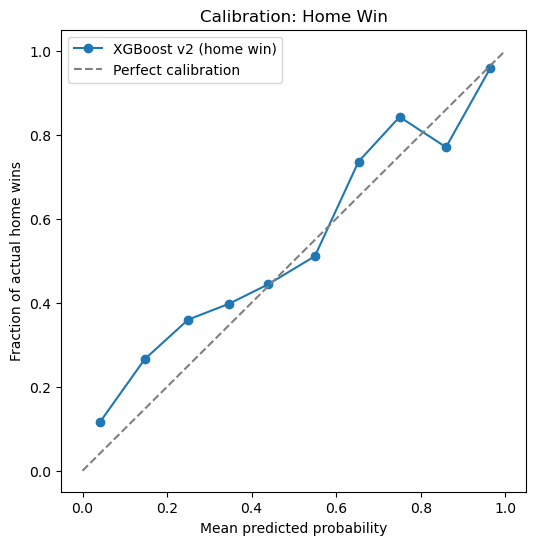

In [99]:
plt.figure(figsize=(6, 6))
plt.plot(mean_predicted_value, fraction_of_positives, marker='o', label='XGBoost v2 (home win)')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfect calibration')
plt.xlabel('Mean predicted probability')
plt.ylabel('Fraction of actual home wins')
plt.legend()
plt.title('Calibration: Home Win')
plt.show()

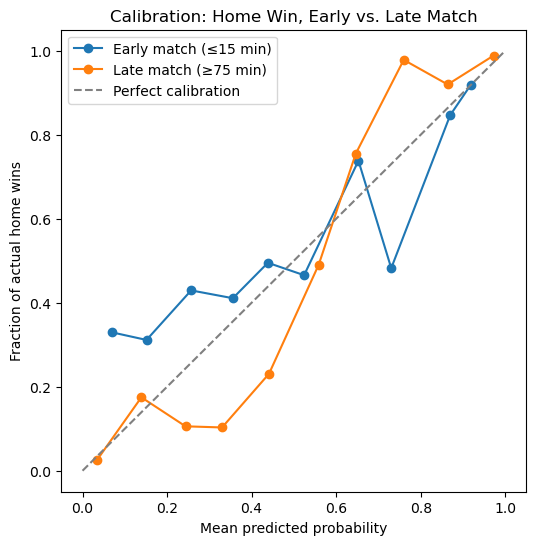

In [100]:
# Early vs late split curve
early_probs_home = early_probs_xgb_v2[:, home_win_idx]
actual_early_home = (early_encoded == home_win_idx).astype(int)
frac_early, mean_pred_early = calibration_curve(actual_early_home, early_probs_home, n_bins=10)

late_probs_home = late_probs_xgb_v2[:, home_win_idx]
actual_late_home = (late_encoded == home_win_idx).astype(int)
frac_late, mean_pred_late = calibration_curve(actual_late_home, late_probs_home, n_bins=10)

plt.figure(figsize=(6, 6))
plt.plot(mean_pred_early, frac_early, marker='o', label='Early match (≤15 min)')
plt.plot(mean_pred_late, frac_late, marker='o', label='Late match (≥75 min)')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfect calibration')
plt.xlabel('Mean predicted probability')
plt.ylabel('Fraction of actual home wins')
plt.legend()
plt.title('Calibration: Home Win, Early vs. Late Match')
plt.show()

In [101]:
# Check early match bin sample issues directly

counts_early, _ = np.histogram(early_probs_home, bins=10, range=(0, 1))
counts_late, _ = np.histogram(late_probs_home, bins=10, range=(0, 1))
print("Early match bin counts:", counts_early)
print("Late match bin counts:", counts_late)

Early match bin counts: [243 334 382 745 816 174 462 141 202 149]
Late match bin counts: [1141  515  350  233   78  104  151  367  510 1120]


Early-match calibration is noisier at higher predicted probabilities due to smaller sample sizes — early in a match, the model rarely produces high-confidence predictions (since it's largely anchored to the prior), so the few times it does, the calibration estimate for that range is less statistically reliable. Late-match calibration is smooth and reliable across the full range, benefiting from far more samples at every confidence level.

## Deliverable Functions

In [102]:
# Confirm classes
print(xgb_model_v2.classes_)
print(label_encoder.classes_)

[0 1 2]
['away_win' 'draw' 'home_win']


In [103]:
# Test both functions on a real snapshot
sample_row = snapshot_skeleton[snapshot_skeleton['match_id'] == 3754291].iloc[45]  # some mid-match snapshot
match_state_sample = sample_row[feature_cols].to_dict()

print(get_live_win_prob(match_state_sample, xgb_model_v2, feature_cols))
print(get_live_fair_odds(match_state_sample, xgb_model_v2, feature_cols))

{'prob_away_win': np.float32(0.21806069), 'prob_draw': np.float32(0.5199649), 'prob_home_win': np.float32(0.26197442)}
{'odds_home': np.float32(3.8171666), 'odds_draw': np.float32(1.9232068), 'odds_away': np.float32(4.5858793)}


## Saving important data

In [104]:
import joblib
joblib.dump(xgb_model_v2, '../data/processed/xgb_live_model.pkl')

['../data/processed/xgb_live_model.pkl']

In [105]:
joblib.dump(label_encoder, '../data/processed/live_model_label_encoder.pkl')

['../data/processed/live_model_label_encoder.pkl']

In [106]:
import json
with open('../data/processed/live_model_feature_cols.json', 'w') as f:
    json.dump(feature_cols, f)

In [107]:
test_model = joblib.load('../data/processed/xgb_live_model.pkl')
test_encoder = joblib.load('../data/processed/live_model_label_encoder.pkl')
with open('../data/processed/live_model_feature_cols.json') as f:
    test_feature_cols = json.load(f)

print(test_feature_cols)
print(test_model.predict_proba(test[test_feature_cols].head(1)))

['home_possession_pct', 'away_possession_pct', 'score_diff', 'home_xg_cum', 'away_xg_cum', 'man_advantage', 'home_shot_momentum', 'away_shot_momentum', 'prob_home_win', 'prob_draw', 'prob_away_win']
[[0.06814202 0.02725495 0.904603  ]]


## Match replay visualization

In [108]:
# Check if this match's predictions already exist
print(3754291 in train['match_id'].values)
print(3754291 in test['match_id'].values)

True
False


In [109]:
# Pull match snapshots and generate predictions for each one
replay_data = snapshot_skeleton[snapshot_skeleton['match_id'] == 3754291].sort_values('snapshot_minute').reset_index(drop=True)

predictions = []
for _, row in replay_data.iterrows():
    match_state = row[feature_cols].to_dict()
    probs = get_live_win_prob(match_state, xgb_model_v2, feature_cols)
    predictions.append(probs)

predictions_df = pd.DataFrame(predictions)
replay_data = pd.concat([replay_data.reset_index(drop=True), predictions_df.add_suffix('_live')], axis=1)

replay_data[['snapshot_minute', 'prob_home_win_live', 'prob_draw_live', 'prob_away_win_live']].head(10)

,snapshot_minute,prob_home_win_live,prob_draw_live,prob_away_win_live
0,0,0.363407,0.320671,0.315922
1,1,0.362200,0.321279,0.316521
2,2,0.362200,0.321279,0.316521
3,3,0.362200,0.321279,0.316521
4,4,0.362200,0.321279,0.316521
5,5,0.362200,0.321279,0.316521
6,6,0.362200,0.321279,0.316521
7,7,0.362200,0.321279,0.316521
8,8,0.362200,0.321279,0.316521
9,9,0.362200,0.321279,0.316521


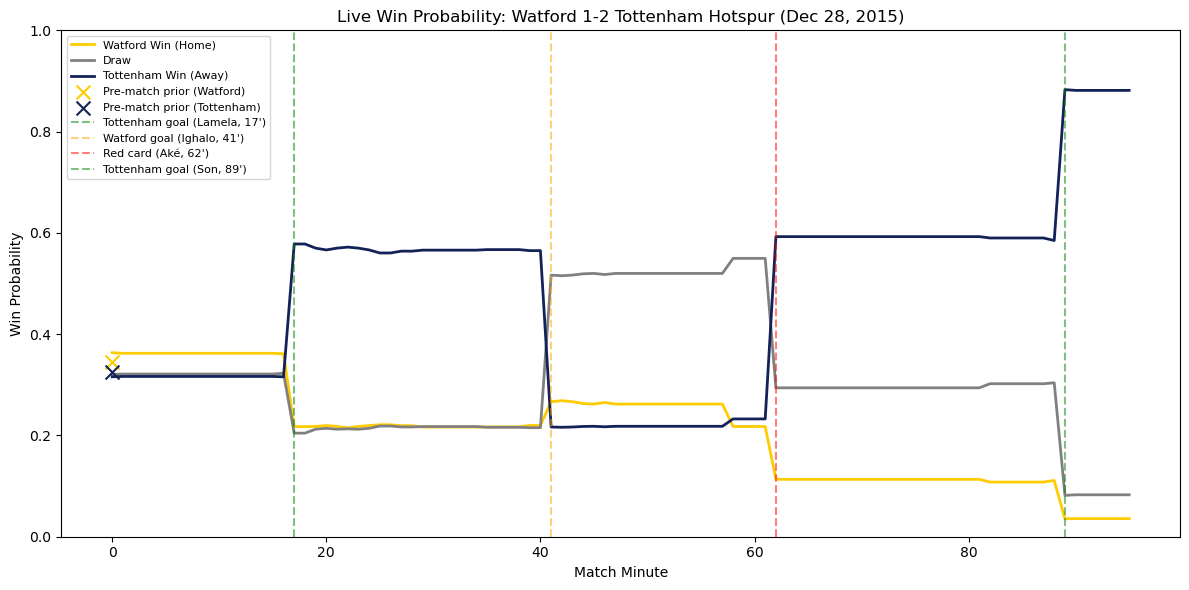

In [110]:
# Plot the match
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(replay_data['snapshot_minute'], replay_data['prob_home_win_live'], label='Watford Win (Home)', color='#FFCC00', linewidth=2)
ax.plot(replay_data['snapshot_minute'], replay_data['prob_draw_live'], label='Draw', color='gray', linewidth=2)
ax.plot(replay_data['snapshot_minute'], replay_data['prob_away_win_live'], label='Tottenham Win (Away)', color='#132257', linewidth=2)

# Mark the pre-match prior as a reference point at minute 0
ax.scatter([0], [replay_data['prob_home_win'].iloc[0]], color='#FFCC00', marker='x', s=100, zorder=5, label='Pre-match prior (Watford)')
ax.scatter([0], [replay_data['prob_away_win'].iloc[0]], color='#132257', marker='x', s=100, zorder=5, label='Pre-match prior (Tottenham)')

# Mark key events
ax.axvline(x=17, color='green', linestyle='--', alpha=0.5, label='Tottenham goal (Lamela, 17\')')
ax.axvline(x=41, color='orange', linestyle='--', alpha=0.5, label='Watford goal (Ighalo, 41\')')
ax.axvline(x=62, color='red', linestyle='--', alpha=0.5, label='Red card (Aké, 62\')')
ax.axvline(x=89, color='green', linestyle='--', alpha=0.5, label='Tottenham goal (Son, 89\')')

ax.set_xlabel('Match Minute')
ax.set_ylabel('Win Probability')
ax.set_title('Live Win Probability: Watford 1-2 Tottenham Hotspur (Dec 28, 2015)')
ax.legend(loc='upper left', fontsize=8)
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()